# M14.1 — Evaluación de la cabeza heterocedástica (4a-G3T, val G3T)

**Pre-registro:** `docs/experiments/M14_1_heteroscedastic.md` (10-11-2026). Criterios aplicados literalmente; una semilla.

**Procedencia** (rutas bajo `<DATA_ROOT>/results/M13_3/`, `DATA_ROOT` vía `src.paths.resolve_data_root`, como en M13_13_G3T_evaluation):

| | tag / checkpoint | fichero |
|---|---|---|
| M14.1 | `M14_1_4a_G3T_hetero_s123` / `M14_1_4a_G3T_hetero_s123_final.pt` | `M14_1_4a_G3T_hetero_s123/val_predictions_embeddings.npz` (μ = `pred_val`, σ = `sigma_val`) |
| Referencia | `M13_13_4a_G3T_s123` / `M13_13_4a_G3T_s123_final.pt` | `M13_13_4a_G3T_s123/val_predictions_embeddings.npz` (el de M13_13_G3T_evaluation) |

- Dataset: `M13_G3_band1024_w16_500k/m13_13_g3t`, split **val** (40 000 filas; split y escalas de etiquetas train-only de M11, contrato G1 congelado vía `load_contract`).
- Unidades: `pred_val`, `sigma_val`, `y_val` estandarizados con el escalador train-only (`y_mean`, `y_std` del npz, que el gate iguala a los del contrato). Paso a físicas: y, μ = x·y_std + y_mean (`npz_to_physical`); σ_phys = σ_std·y_std.
- τ30 y deciles: código de M13_13_G3T_evaluation (celda 3), sin cambios.
- **Fuente del SNR:** `target_network_snr` del HDF5 de **G3** (bloque `dataset` de `configs/experiments/m13/train_m13_4a_G3aug_s123.json`, como en M13_8 celda 3), alineado por `idx_val`. El build de G3T (`scripts/m13/m13_13_build_g3t.py`) no guarda un SNR por fila. *SNR nominal de G3 (calculado con el escalón inicial); en masas altas sobreestima el SNR de G3T; solo afecta a la asignación de terciles cerca de los cortes; elección fijada antes de ver resultados (el pre-registro no especificaba la fuente).*
- Orden de etiquetas: `[chirp_mass, total_mass, chi_eff]`. Residuo r = μ − y; z = (y − μ)/σ.

**Criterios pre-registrados (val G3T):**
1. *Salvaguarda:* ΔRMSE% = 100·(RMSE_M14.1/RMSE_ref − 1) por etiqueta, global; IC 95 % percentil por bootstrap emparejado de filas, B = 2000, `default_rng(141001)`. PASA si IC_sup ≤ +4; FALLA si el punto > +4; INDETERMINADO en otro caso. Global: PASA si las tres pasan.
2. *Calibración:* std(z) (ddof = 1) en [0,9; 1,1] en las 21 celdas: 3 etiquetas × {global, SNR-T1..T3, D1–D3, D4–D7, D8–D10}. PASA si las 21 pasan.
3. *Descriptivo:* σ_media/RMSE por tercil de SNR (adaptado si está en [0,8; 1,2]); Spearman(σ, |r|).

**Adopción para el Mondrian v2:** C1 PASA y C2 PASA. No se puede concluir el beneficio en anchura de los intervalos (requiere cal/test).

In [1]:
# 1. Parámetros, procedencia y CONFIG
import json
import sys
import warnings
from datetime import datetime, timezone
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import norm, spearmanr

ROOT = Path.cwd().resolve()
while not (ROOT / 'AGENTS.md').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.paths import resolve_data_root, resolve_processed_artifact
# Read-only reuse, as in M13_13_G3T_evaluation: pinned G1 contract and tau30 of M13.1.
from scripts.m12.m12_5_3_posthoc_check import LABELS, digest, load_contract, npz_to_physical, require
from scripts.m13.m13_1_diagnostics import tau_newtonian

cfg = json.loads((ROOT / 'configs/experiments/train_m11_final_G1_500k.json').read_text())
DATA_ROOT = resolve_data_root(config_data_root=cfg.get('data_root'))
M13_DIR = DATA_ROOT / 'results' / 'M13_3'
VAL_NPZ = 'val_predictions_embeddings.npz'

# ---- Names and inputs (figures and tables take model and label names from here) --------------------------------
CONFIG = dict(
    models=dict(
        hetero=dict(tag='M14_1_4a_G3T_hetero_s123', name='M14.1 (4a-G3T hetero s123)'),
        ref=dict(tag='M13_13_4a_G3T_s123', name='4a-G3T s123 (ref.)'),
    ),
    labels={'chirp_mass': 'chirp mass', 'total_mass': 'total mass', 'chi_eff': 'χ_eff'},
    units={'chirp_mass': 'M☉', 'total_mass': 'M☉', 'chi_eff': 'adim.'},
    colors=dict(sigma='#2a6fb0', rmse='#c4512b', hetero='#2a6fb0', ref='0.35', neutral='0.5'),
)
TAG_H, TAG_R = CONFIG['models']['hetero']['tag'], CONFIG['models']['ref']['tag']
PRED_H = M13_DIR / TAG_H / VAL_NPZ
PRED_R = M13_DIR / TAG_R / VAL_NPZ                 # reference npz of M13_13_G3T_evaluation (PRED_G3T_ON_G3T)
OUT_DIR = M13_DIR / TAG_H
FIG_DIR = OUT_DIR / 'figures'
REF_SUMMARY = M13_DIR / 'M13_6_evaluation_summary_20261102_1552.json'   # optional: tau_edges_s of M13_6, as in M13_13
# SNR source (fixed before seeing results): G3 HDF5 of the 4a-aug G3 training config, as in M13_8 cell 1/3.
G3_CFG = ROOT / 'configs/experiments/m13/train_m13_4a_G3aug_s123.json'
SNR_KEY = 'target_network_snr'
SNR_SOURCE = ('G3 nominal target_network_snr (G3 HDF5 of train_m13_4a_G3aug_s123.json), aligned by idx_val; '
              'G3T build does not store a per-row SNR')
# -----------------------------------------------------------------------------------------------------------------

# Gates.
N_EXPECTED = 40000
MSE_LOG = np.array([0.1018, 0.0643, 0.1452])   # standardized val MSE of mu, last epoch of the M14.1 log
MSE_LOG_MEAN = 0.10376
MSE_TOL = 5e-4
RMSE_REF_C = [(5.25, 2), (8.76, 2), (0.168, 3)]  # M13.13 C, physical RMSE of 4a-G3T s123 on val G3T (value, decimals)
Y_RTOL, Y_ATOL = 1e-5, 1e-6                    # y of G3 HDF5 vs npz y (float32 inverse standardisation), as M13_13
TAU_EDGE_RTOL = 1e-6
G3T_MARK = 'm13_13_g3t'

# Pre-registered settings (doc M14.1).
N_BOOT = 2000
BLOCK = 200                                    # replicates per vectorised block (memory only; does not change draws)
SEED_C1 = 141001                               # C1, then the descriptive ΔRMSE groups (same generator, fixed order)
SEED_C2 = 141002                               # descriptive CI of std(z)
C1_MAX_PCT = 4.0
STDZ_BAND = (0.9, 1.1)
ADAPT_BAND = (0.8, 1.2)
RUN_UTC = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')

g3_ds = json.loads(G3_CFG.read_text())['dataset']
require(G3T_MARK not in g3_ds['dataset_id'], f'{G3_CFG.name}: dataset block is not G3')
G3_H5 = resolve_processed_artifact(data_root=DATA_ROOT, dataset_id=g3_ds['dataset_id'], file_name=g3_ds['dataset_file'])

all_files = {'pred/hetero': PRED_H, 'pred/ref': PRED_R, 'snr/G3_h5': G3_H5}
missing = [f'{k}: {p}' for k, p in all_files.items() if not p.exists()]
require(not missing, f'Missing files (required): {missing}')
sha = {k: digest(p) for k, p in all_files.items() if k.startswith('pred/')}   # the HDF5 is not hashed (size)
prov = pd.DataFrame([dict(file=k, path=str(p), size_mb=p.stat().st_size / 2**20,
                          mtime_utc=datetime.fromtimestamp(p.stat().st_mtime, timezone.utc).isoformat(timespec='seconds'),
                          sha256_short=sha.get(k, '')[:12]) for k, p in all_files.items()])
print(DATA_ROOT)
print('Run stamp:', RUN_UTC)
prov

/data/vserrano/cbc_pe_data
Run stamp: 20261111T114355Z


,file,path,size_mb,mtime_utc,sha256_short
0,pred/hetero,/data/vserrano/cbc_pe_data/results/M13_3/M14_1...,10.395356,2026-11-11T02:15:24+00:00,f2303c011e88
1,pred/ref,/data/vserrano/cbc_pe_data/results/M13_3/M13_1...,10.004542,2026-11-07T00:19:54+00:00,92db8eb185ec
2,snr/G3_h5,/data/vserrano/cbc_pe_data/processed/M13_G3_ba...,94112.321022,2026-10-27T13:42:24+00:00,


In [2]:
# 1b. Carga y GATES (require aborts on the first failure)
paths, splits, c_mean, c_std, identity = load_contract(DATA_ROOT)
checks = ['frozen G1 contract (g1_npe_contract.load_contract)']
gates = {}


def check(ok, name):
    require(bool(ok), 'Check failed: ' + name)
    checks.append(name)


def load_val(path, name, ckpt_expected, with_sigma):
    # Adapted from load_pred of M13_13_G3T_evaluation (cell 2), plus sigma_val. Only the keys below are read: the npz
    # also holds an object array (model_config) that is never accessed, so allow_pickle stays False. No reordering:
    # the trainer writes idx_val ascending, and G1 requires the same order in both files.
    with np.load(path, allow_pickle=False) as a:
        keys = set(a.files)                       # names only; no array is decompressed
        if with_sigma:
            check('sigma_val' in keys, f'{name}: sigma_val present')
        f_s = a['pred_val'].astype(np.float64)
        y_raw = a['y_val']                        # as stored, for the bitwise identity gate
        idx = a['idx_val'].astype(np.int64)
        y_mean, y_std = a['y_mean'].astype(np.float64), a['y_std'].astype(np.float64)
        label_names = a['label_names'].tolist()
        split_name = Path(str(a['split_path'])).name
        ckpt_name = Path(str(a['checkpoint_file'])).name if 'checkpoint_file' in keys else None
        memmap_dir = str(a['memmap_dir']) if 'memmap_dir' in keys else None
        s_s = a['sigma_val'].astype(np.float64) if with_sigma else None
    y_s = y_raw.astype(np.float64)
    n = len(idx)
    check(f_s.shape == y_s.shape == (n, 3), f'{name}: shapes')
    check(label_names == LABELS, f'{name}: label order {LABELS}')
    check(split_name == paths['split_file'].name, f'{name}: split_path is the pinned split file')
    check(np.allclose(y_mean, c_mean, rtol=1e-6) and np.allclose(y_std, c_std, rtol=1e-6, atol=1e-8),
          f'{name}: npz y_mean/y_std equal M11 train-only label stats')
    check(np.all(np.diff(idx) > 0), f'{name}: idx_val strictly ascending (no duplicates)')
    check(np.isfinite(f_s).all() and np.isfinite(y_s).all(), f'{name}: finite pred/y')
    check(ckpt_name == ckpt_expected, f'{name}: checkpoint is {ckpt_expected}')
    check(memmap_dir is not None and G3T_MARK in memmap_dir, f'{name}: memmap_dir is under {G3T_MARK}')
    y, f, units = npz_to_physical(y_s, f_s, c_mean, c_std)
    check(units == 'standardized', f'{name}: npz pred/y standardized (trainer contract)')
    check(np.all(np.abs(f.mean(0) - y.mean(0)) < 0.1 * c_std), f'{name}: pred in units of y')
    return dict(f=f, y=y, f_s=f_s, y_s=y_s, y_raw=y_raw, s_s=s_s, idx=idx, ckpt=ckpt_name, memmap_dir=memmap_dir)


H = load_val(PRED_H, 'hetero', f'{TAG_H}_final.pt', True)
Rf = load_val(PRED_R, 'ref', f'{TAG_R}_final.pt', False)

# G1: same rows, same order, N = 40 000, identical y_val.
IDX = H['idx']
check(np.array_equal(Rf['idx'], IDX), 'G1: identical idx_val (same rows, same order)')
check(len(IDX) == N_EXPECTED, f'G1: N = {N_EXPECTED}')
check(np.array_equal(IDX, np.sort(splits['val'])), 'G1: idx_val equals val membership')
check(H['y_raw'].dtype == Rf['y_raw'].dtype and np.array_equal(H['y_raw'], Rf['y_raw']), 'G1: identical y_val (bitwise)')
check(not np.array_equal(H['f_s'], Rf['f_s']), 'G1: M14.1 and reference predictions differ')
gates['G1'] = dict(n=int(len(IDX)), idx_identical=True, y_identical=True)

# G2: sigma > 0 and finite in every row.
check(H['s_s'].shape == H['f_s'].shape, 'G2: sigma_val shape')
check(np.isfinite(H['s_s']).all() and np.all(H['s_s'] > 0), 'G2: sigma finite and > 0 in every row')
gates['G2'] = dict(sigma_std_min=H['s_s'].min(0), sigma_std_max=H['s_s'].max(0))

# G3: standardized MSE of mu reproduces the last-epoch log of M14.1.
mse_std = np.mean((H['f_s'] - H['y_s'])**2, 0)
print('G3 standardized MSE of mu:', dict(zip(LABELS, mse_std.round(5))), '| mean', round(float(mse_std.mean()), 5))
check(np.all(np.abs(mse_std - MSE_LOG) <= MSE_TOL), f'G3: per-label standardized MSE = {MSE_LOG.tolist()} (tol {MSE_TOL:g})')
check(abs(mse_std.mean() - MSE_LOG_MEAN) <= MSE_TOL, f'G3: mean standardized MSE = {MSE_LOG_MEAN} (tol {MSE_TOL:g})')
gates['G3'] = dict(mse_std=mse_std, mse_std_mean=float(mse_std.mean()), log=MSE_LOG, log_mean=MSE_LOG_MEAN, tol=MSE_TOL)

# G4: physical RMSE of the reference reproduces M13.13 C (to the rounding).
Y = H['y']
rmse_ref_g4 = np.sqrt(np.mean((Rf['f'] - Y)**2, 0))
print('G4 physical RMSE of the reference:', dict(zip(LABELS, rmse_ref_g4.round(4))))
for j, (v, d) in enumerate(RMSE_REF_C):
    check(abs(round(float(rmse_ref_g4[j]), d) - v) < 1e-9, f'G4: RMSE_ref {LABELS[j]} rounds to {v}')
gates['G4'] = dict(rmse_ref=rmse_ref_g4, expected=[v for v, _ in RMSE_REF_C])

# Physical units. sigma_phys = sigma_std * y_std (train-only scale per label), same scale as npz_to_physical uses.
F_H, F_R = H['f'], Rf['f']                    # mu of M14.1 and reference prediction, physical
S = H['s_s'] * c_std                          # sigma_phys
R_H, R_R = F_H - Y, F_R - Y                   # residuals r = f - y
Z = (Y - F_H) / S                             # z = (y - mu)/sigma (unit-invariant)
N = len(Y)
print('GATES passed:', len(checks), 'checks | n_val:', N)

G3 standardized MSE of mu: {'chirp_mass': np.float64(0.10182), 'total_mass': np.float64(0.06428), 'chi_eff': np.float64(0.14518)} | mean 0.10376
G4 physical RMSE of the reference: {'chirp_mass': np.float64(5.248), 'total_mass': np.float64(8.7598), 'chi_eff': np.float64(0.1677)}
GATES passed: 34 checks | n_val: 40000


In [3]:
# 2. Grupos: global, tau30 (D1-D3, D4-D7, D8-D10; D10 descriptive) y terciles de SNR
# tau30 deciles: code of M13_13_G3T_evaluation cell 3, unchanged (Newtonian tau30 of the TRUE Mc, val quantile edges).
tau30 = tau_newtonian(Y[:, 0])
tau_edges = np.quantile(tau30, np.linspace(0, 1, 11))
tdec = np.clip(np.searchsorted(tau_edges[1:-1], tau30, side='right'), 0, 9)
DEC = [f'D{d + 1}' for d in range(10)]
TAU_GROUPS = ['D1-D3', 'D4-D7', 'D8-D10']
GROUPS = {**{k: tdec == d for d, k in enumerate(DEC)}, 'D1-D3': tdec <= 2, 'D4-D7': (tdec >= 3) & (tdec <= 6),
          'D8-D10': tdec >= 7, 'global': np.ones(N, bool)}

ref_summary = json.loads(REF_SUMMARY.read_text()) if REF_SUMMARY.exists() else {}
if 'tau_edges_s' in ref_summary:
    check(np.allclose(tau_edges, ref_summary['tau_edges_s'], rtol=TAU_EDGE_RTOL, atol=0), 'tau30 decile edges equal M13_6 summary')
else:
    warnings.warn(f'{REF_SUMMARY.name}: tau_edges_s not available; edges not compared')
check(sum(int(GROUPS[k].sum()) for k in TAU_GROUPS) == N, 'tau groups partition val')

# SNR as in M13_8 cell 3: target_network_snr of the G3 HDF5 at the sorted val rows. Alignment gate: every idx_val exists
# in the HDF5, idx_val is ascending (h5py fancy indexing keeps that order) and the HDF5 labels at those rows equal Y.
with h5py.File(G3_H5, 'r') as h:
    require(SNR_KEY in h, f'G3 HDF5 lacks {SNR_KEY}')
    n_h5 = h[SNR_KEY].shape[0]
    check(IDX.min() >= 0 and IDX.max() < n_h5, 'SNR: every idx_val exists in the G3 HDF5')
    check(np.all(np.diff(IDX) > 0), 'SNR: idx_val ascending (read order = npz order)')
    SNR = h[SNR_KEY][IDX].astype(np.float64)
    y_h5 = h['y'][IDX].astype(np.float64)
check(SNR.shape == (N,) and np.isfinite(SNR).all() and np.all(SNR > 0), f'{SNR_KEY} finite and positive')
print('max |y_G3h5 - y_npz| (physical):', np.abs(y_h5 - Y).max(0))
check(np.isclose(y_h5, Y, rtol=Y_RTOL, atol=Y_ATOL).all(), 'SNR: G3 HDF5 labels at idx_val equal y_val (row order matches)')

SNR_CUTS = np.quantile(SNR, [1 / 3, 2 / 3])
ter = np.searchsorted(SNR_CUTS, SNR, side='right')        # 0, 1, 2 (as M13_8 cell 9)
SNR_GROUPS = ['SNR-T1', 'SNR-T2', 'SNR-T3']
GROUPS.update({k: ter == t for t, k in enumerate(SNR_GROUPS)})
check(sum(int(GROUPS[k].sum()) for k in SNR_GROUPS) == N, 'SNR terciles partition val')

CELL_GROUPS = ['global'] + SNR_GROUPS + TAU_GROUPS                       # the 7 groups of criterion 2
DESC_GROUPS = ['D1-D3', 'D4-D7', 'D8-D10', 'D10'] + SNR_GROUPS          # fixed order of the descriptive bootstrap
print('SNR tercile cuts (val quantiles 1/3, 2/3):', SNR_CUTS)
print('sizes:', {k: int(GROUPS[k].sum()) for k in CELL_GROUPS + ['D10']})

max |y_G3h5 - y_npz| (physical): [2.34669051e-06 7.88831312e-06 6.16673788e-08]
SNR tercile cuts (val quantiles 1/3, 2/3): [14.95404436 19.98007806]
sizes: {'global': 40000, 'SNR-T1': 13333, 'SNR-T2': 13333, 'SNR-T3': 13334, 'D1-D3': 12000, 'D4-D7': 16000, 'D8-D10': 12000, 'D10': 4000}


## Criterio 1 — salvaguarda (pre-registrado)
ΔRMSE% de μ frente a la referencia, por etiqueta, global. Bootstrap emparejado de filas: una extracción por réplica, compartida por los dos modelos, la etiqueta verdadera y las tres etiquetas. `default_rng(141001)`, B = 2000, bloques de 200.

In [4]:
# 3. CRITERIO 1
E2_H, E2_R = R_H**2, R_R**2
rng_c1 = np.random.default_rng(SEED_C1)       # consumed here (global) and then in cell 4, in that fixed order


def drmse_boot(rows, rng):
    eh, er = E2_H[rows], E2_R[rows]
    n = len(eh)
    rh, rr = np.sqrt(eh.mean(0)), np.sqrt(er.mean(0))
    reps = np.empty((N_BOOT, 3))
    for s in range(0, N_BOOT, BLOCK):
        m = min(BLOCK, N_BOOT - s)
        ii = rng.integers(0, n, size=(m, n))
        reps[s:s + m] = 100.0 * (np.sqrt(eh[ii].mean(1)) / np.sqrt(er[ii].mean(1)) - 1.0)
    return rh, rr, 100.0 * (rh / rr - 1.0), reps


def drmse_table(group, rows, rng):
    rh, rr, pt, reps = drmse_boot(rows, rng)
    lo, hi = np.percentile(reps, [2.5, 97.5], axis=0)
    return [dict(group=group, label=lab, n=int(rows.sum()), rmse_ref=rr[j], rmse_hetero=rh[j], drmse_pct=pt[j],
                 ci95_lo=lo[j], ci95_hi=hi[j]) for j, lab in enumerate(LABELS)]


def c1_verdict(pt, hi):
    if hi <= C1_MAX_PCT:
        return 'PASA'
    if pt > C1_MAX_PCT:
        return 'FALLA'
    return 'INDETERMINADO'


T_C1 = pd.DataFrame(drmse_table('global', GROUPS['global'], rng_c1))
T_C1['verdict'] = [c1_verdict(p, h) for p, h in zip(T_C1.drmse_pct, T_C1.ci95_hi)]
C1_VERDICT = 'PASA' if (T_C1.verdict == 'PASA').all() else 'NO PASA'
with pd.option_context('display.float_format', '{:.4g}'.format, 'display.width', 200):
    display(T_C1)
print('CRITERIO 1 (global):', C1_VERDICT)

,group,label,n,rmse_ref,rmse_hetero,drmse_pct,ci95_lo,ci95_hi,verdict
0,global,chirp_mass,40000,5.248,5.268,0.3726,-0.03121,0.8245,PASA
1,global,total_mass,40000,8.76,8.799,0.4447,-0.03625,0.9427,PASA
2,global,chi_eff,40000,0.1677,0.1678,0.06232,-0.347,0.4816,PASA


CRITERIO 1 (global): PASA


## Descriptivo, NO pre-registrado — ΔRMSE% por grupo
Mismo cálculo dentro de cada grupo (bootstrap dentro del grupo), con el mismo generador de C1 continuando en el orden fijo D1–D3, D4–D7, D8–D10, D10, SNR-T1, SNR-T2, SNR-T3. Sin veredicto.

**Recordatorio:** el ruido de semilla de 4a es 1,6–2,0 % en ΔRMSE global y 4,7 % en χ_eff D10. El bootstrap de filas no lo incluye: estos IC no representan la variación entre entrenamientos (una sola semilla).

In [5]:
# 4. DESCRIPTIVO (no pre-registrado): ΔRMSE% por grupo de tau30, D10 y terciles de SNR
T_DESC = pd.DataFrame([r for k in DESC_GROUPS for r in drmse_table(k, GROUPS[k], rng_c1)])
with pd.option_context('display.float_format', '{:.4g}'.format, 'display.width', 200):
    display(T_DESC)

,group,label,n,rmse_ref,rmse_hetero,drmse_pct,ci95_lo,ci95_hi
0,D1-D3,chirp_mass,12000,6.121,6.161,0.6445,-0.09602,1.377
1,D1-D3,total_mass,12000,10.31,10.44,1.29,0.5433,2.052
2,D1-D3,chi_eff,12000,0.1808,0.1823,0.836,0.295,1.371
3,D4-D7,chirp_mass,16000,5.397,5.411,0.2542,-0.3355,0.9057
4,D4-D7,total_mass,16000,8.482,8.53,0.5646,-0.2263,1.504
5,D4-D7,chi_eff,16000,0.1513,0.1515,0.1261,-0.3837,0.6875
6,D8-D10,chirp_mass,12000,3.937,3.937,0.01003,-1.222,1.281
7,D8-D10,total_mass,12000,7.318,7.21,-1.474,-2.49,-0.4516
8,D8-D10,chi_eff,12000,0.1746,0.1731,-0.8388,-1.814,0.1523
9,D10,chirp_mass,4000,2.168,2.151,-0.8,-5.773,4.011


## Criterio 2 — calibración (pre-registrado)
std(z), ddof = 1, en 21 celdas (3 etiquetas × {global, SNR-T1..T3, D1–D3, D4–D7, D8–D10}); PASA por celda si está en [0,9; 1,1]. El IC bootstrap de std(z) (`default_rng(141002)`, B = 2000, una extracción por réplica compartida por las tres etiquetas, grupos en el orden de la tabla) es descriptivo y no entra en el veredicto.

In [6]:
# 5. CRITERIO 2
rng_c2 = np.random.default_rng(SEED_C2)
rows = []
for k in CELL_GROUPS:
    z = Z[GROUPS[k]]
    n = len(z)
    sd = z.std(0, ddof=1)
    reps = np.empty((N_BOOT, 3))
    for s in range(0, N_BOOT, BLOCK):
        m = min(BLOCK, N_BOOT - s)
        ii = rng_c2.integers(0, n, size=(m, n))
        reps[s:s + m] = z[ii].std(1, ddof=1)
    lo, hi = np.percentile(reps, [2.5, 97.5], axis=0)
    for j, lab in enumerate(LABELS):
        rows.append(dict(label=lab, group=k, n=n, std_z=sd[j],
                         verdict='PASA' if STDZ_BAND[0] <= sd[j] <= STDZ_BAND[1] else 'FALLA',
                         ci95_lo_descr=lo[j], ci95_hi_descr=hi[j]))
T_C2 = pd.DataFrame(rows)
check(len(T_C2) == 21, 'criterion 2: 21 cells')
C2_VERDICT = 'PASA' if (T_C2.verdict == 'PASA').all() else 'FALLA'
with pd.option_context('display.float_format', '{:.4f}'.format, 'display.width', 200):
    display(T_C2.pivot(index='group', columns='label', values='std_z').loc[CELL_GROUPS, LABELS])
    display(T_C2)
print('CRITERIO 2:', C2_VERDICT, f'({int((T_C2.verdict == "PASA").sum())}/21 celdas en [{STDZ_BAND[0]}, {STDZ_BAND[1]}])')

label,chirp_mass,total_mass,chi_eff
group,,,
global,0.9915,1.0005,1.0022
SNR-T1,1.0024,1.0034,1.0014
SNR-T2,0.9949,1.0037,1.0113
SNR-T3,0.9770,0.9944,0.9940
D1-D3,0.8321,0.9075,0.9750
D4-D7,1.0109,0.9825,0.9706
D8-D10,1.0067,1.0180,1.0250


,label,group,n,std_z,verdict,ci95_lo_descr,ci95_hi_descr
0,chirp_mass,global,40000,0.9915,PASA,0.9832,0.9998
1,total_mass,global,40000,1.0005,PASA,0.9927,1.0082
2,chi_eff,global,40000,1.0022,PASA,0.9952,1.0091
3,chirp_mass,SNR-T1,13333,1.0024,PASA,0.9877,1.0170
4,total_mass,SNR-T1,13333,1.0034,PASA,0.9895,1.0167
5,chi_eff,SNR-T1,13333,1.0014,PASA,0.9891,1.0137
6,chirp_mass,SNR-T2,13333,0.9949,PASA,0.9812,1.0087
7,total_mass,SNR-T2,13333,1.0037,PASA,0.9896,1.0180
8,chi_eff,SNR-T2,13333,1.0113,PASA,0.9981,1.0239
9,chirp_mass,SNR-T3,13334,0.9770,PASA,0.9641,0.9901


CRITERIO 2: FALLA (20/21 celdas en [0.9, 1.1])


## Descriptivo pre-registrado (punto 3 del doc)
σ_media/RMSE por etiqueta y tercil de SNR, con σ_media = mean(σ_phys) (definición literal del doc) y RMSE de μ (M14.1); "adaptado" si está en [0,8; 1,2]. Spearman(σ, |r|) global y por grupo de τ30.

*Complemento (no pre-registrado):* RMS(σ)/RMSE = sqrt(mean σ²)/RMSE, la magnitud comparable con 1 si std(z) ≈ 1.

In [7]:
# 6. DESCRIPTIVO pre-registrado: sigma_media / RMSE por tercil de SNR; Spearman(sigma, |r|)
rows = []
for k in SNR_GROUPS:
    g = GROUPS[k]
    rmse = np.sqrt(np.mean(R_H[g]**2, 0))
    s_mean, s_rms = S[g].mean(0), np.sqrt(np.mean(S[g]**2, 0))
    for j, lab in enumerate(LABELS):
        ratio = s_mean[j] / rmse[j]
        rows.append(dict(label=lab, group=k, n=int(g.sum()), snr_median=np.median(SNR[g]), rmse_hetero=rmse[j],
                         sigma_mean=s_mean[j], sigma_mean_over_rmse=ratio,
                         adapted=bool(ADAPT_BAND[0] <= ratio <= ADAPT_BAND[1]),
                         sigma_rms=s_rms[j], sigma_rms_over_rmse_compl=s_rms[j] / rmse[j]))
T_ADAPT = pd.DataFrame(rows)

T_SPEAR = pd.DataFrame([dict(label=lab, group=k, n=int(GROUPS[k].sum()),
                             spearman=float(spearmanr(S[GROUPS[k], j], np.abs(R_H[GROUPS[k], j]))[0]))
                        for j, lab in enumerate(LABELS) for k in ['global'] + TAU_GROUPS])
with pd.option_context('display.float_format', '{:.4g}'.format, 'display.width', 200):
    display(T_ADAPT)
    display(T_SPEAR.pivot(index='group', columns='label', values='spearman').loc[['global'] + TAU_GROUPS, LABELS])

,label,group,n,snr_median,rmse_hetero,sigma_mean,sigma_mean_over_rmse,adapted,sigma_rms,sigma_rms_over_rmse_compl
0,chirp_mass,SNR-T1,13333,12.46,6.398,5.467,0.8545,True,6.424,1.004
1,total_mass,SNR-T1,13333,12.46,11.15,10.3,0.9237,True,11.09,0.9949
2,chi_eff,SNR-T1,13333,12.46,0.2096,0.202,0.9634,True,0.2099,1.001
3,chirp_mass,SNR-T2,13333,17.46,5.008,4.185,0.8358,True,5.069,1.012
4,total_mass,SNR-T2,13333,17.46,8.09,7.484,0.9252,True,8.18,1.011
5,chi_eff,SNR-T2,13333,17.46,0.1567,0.1497,0.9554,True,0.1557,0.9935
6,chirp_mass,SNR-T3,13334,22.45,4.151,3.447,0.8306,True,4.185,1.008
7,total_mass,SNR-T3,13334,22.45,6.521,6.015,0.9224,True,6.554,1.005
8,chi_eff,SNR-T3,13334,22.45,0.1262,0.1221,0.967,True,0.1267,1.004


label,chirp_mass,total_mass,chi_eff
group,,,
global,0.6547,0.4754,0.3586
D1-D3,0.3882,0.292,0.3259
D4-D7,0.4829,0.4198,0.2651
D8-D10,0.6783,0.538,0.4587


## Descriptivo, NO pre-registrado — mean(z), RMS(z) y cobertura empírica
Por celda (las 21 de C2): mean(z), RMS(z) y cobertura empírica de μ ± 1σ y μ ± 1,645σ frente a la nominal gaussiana (0,683 y 0,90).

In [8]:
# 7. DESCRIPTIVO (no pre-registrado): mean(z), RMS(z), coberturas
COV_K = [1.0, 1.645]
COV_NOMINAL = {kk: float(2 * norm.cdf(kk) - 1) for kk in COV_K}
rows = []
for k in CELL_GROUPS:
    z = Z[GROUPS[k]]
    for j, lab in enumerate(LABELS):
        r = dict(label=lab, group=k, n=len(z), mean_z=z[:, j].mean(), rms_z=np.sqrt(np.mean(z[:, j]**2)))
        for kk in COV_K:
            r[f'cov_{kk:g}sigma'] = np.mean(np.abs(z[:, j]) <= kk)
            r[f'nominal_{kk:g}sigma'] = COV_NOMINAL[kk]
        rows.append(r)
T_Z = pd.DataFrame(rows)
with pd.option_context('display.float_format', '{:.4f}'.format, 'display.width', 220):
    display(T_Z)

,label,group,n,mean_z,rms_z,cov_1sigma,nominal_1sigma,cov_1.645sigma,nominal_1.645sigma
0,chirp_mass,global,40000,0.0181,0.9916,0.6986,0.6827,0.9111,0.9000
1,total_mass,global,40000,0.0009,1.0005,0.6880,0.6827,0.9079,0.9000
2,chi_eff,global,40000,0.0082,1.0023,0.6782,0.6827,0.9031,0.9000
3,chirp_mass,SNR-T1,13333,0.0260,1.0027,0.6917,0.6827,0.9086,0.9000
4,total_mass,SNR-T1,13333,0.0068,1.0034,0.6860,0.6827,0.9084,0.9000
5,chi_eff,SNR-T1,13333,0.0121,1.0014,0.6784,0.6827,0.9053,0.9000
6,chirp_mass,SNR-T2,13333,0.0122,0.9949,0.7016,0.6827,0.9089,0.9000
7,total_mass,SNR-T2,13333,-0.0009,1.0037,0.6894,0.6827,0.9065,0.9000
8,chi_eff,SNR-T2,13333,0.0075,1.0113,0.6796,0.6827,0.8994,0.9000
9,chirp_mass,SNR-T3,13334,0.0160,0.9771,0.7026,0.6827,0.9156,0.9000


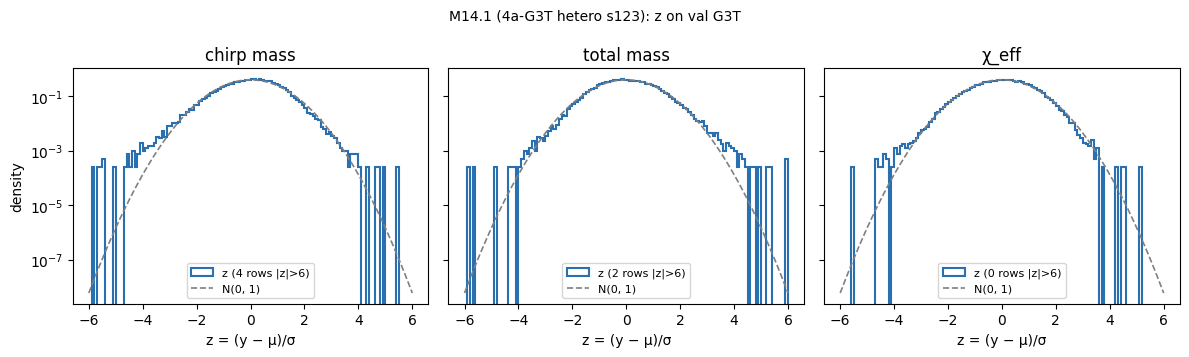

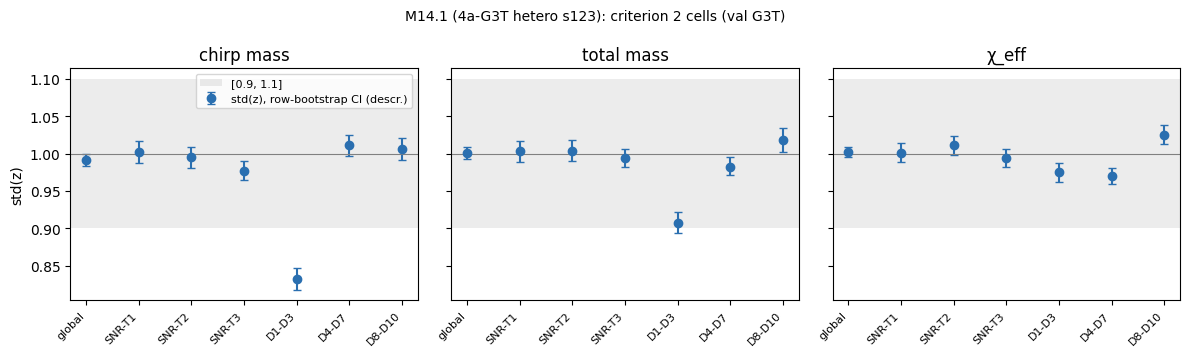

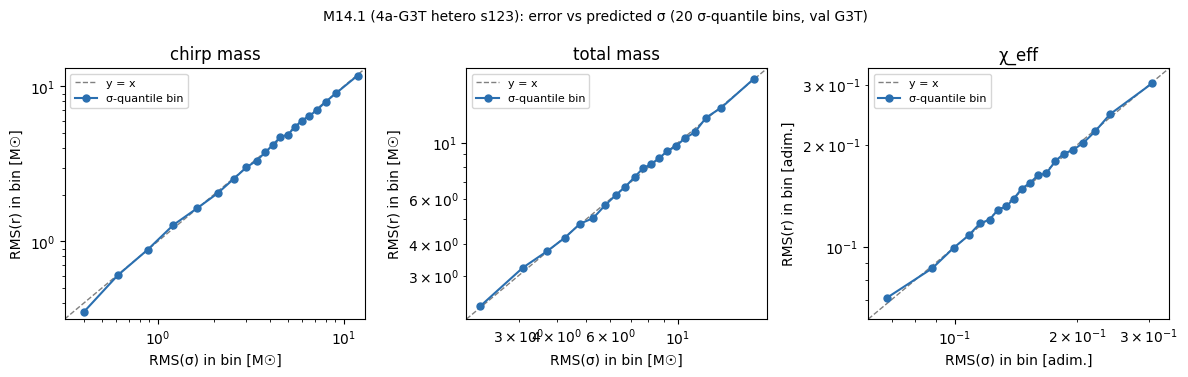

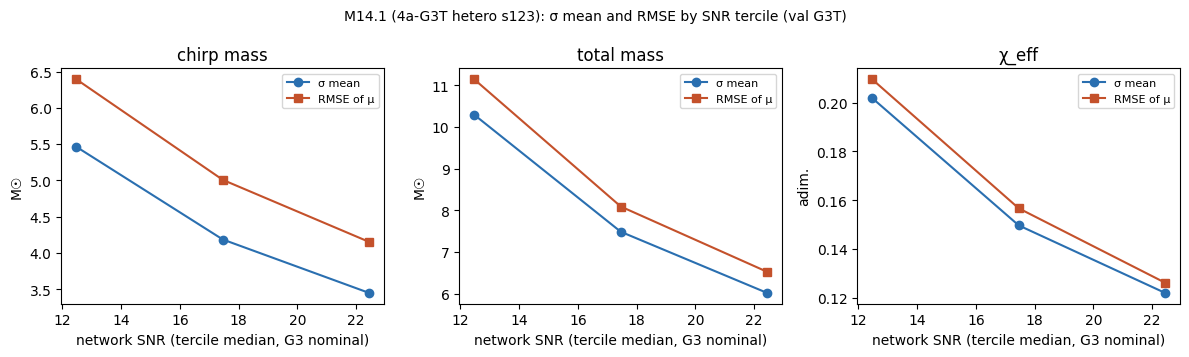

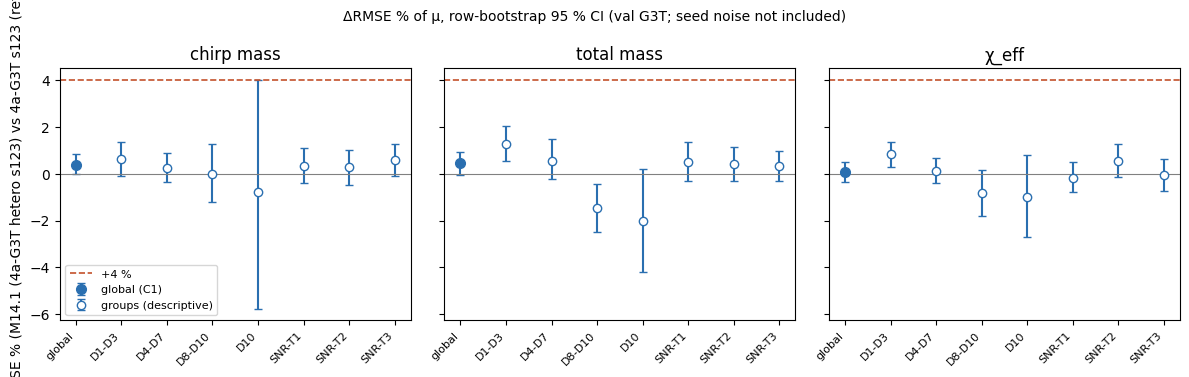

saved /data/vserrano/cbc_pe_data/results/M13_3/M14_1_4a_G3T_hetero_s123/figures/M14_1_a_z_hist_20261111T114355Z.png
saved /data/vserrano/cbc_pe_data/results/M13_3/M14_1_4a_G3T_hetero_s123/figures/M14_1_a_z_hist_20261111T114355Z.pdf
saved /data/vserrano/cbc_pe_data/results/M13_3/M14_1_4a_G3T_hetero_s123/figures/M14_1_b_std_z_cells_20261111T114355Z.png
saved /data/vserrano/cbc_pe_data/results/M13_3/M14_1_4a_G3T_hetero_s123/figures/M14_1_b_std_z_cells_20261111T114355Z.pdf
saved /data/vserrano/cbc_pe_data/results/M13_3/M14_1_4a_G3T_hetero_s123/figures/M14_1_c_rms_r_vs_sigma_20261111T114355Z.png
saved /data/vserrano/cbc_pe_data/results/M13_3/M14_1_4a_G3T_hetero_s123/figures/M14_1_c_rms_r_vs_sigma_20261111T114355Z.pdf
saved /data/vserrano/cbc_pe_data/results/M13_3/M14_1_4a_G3T_hetero_s123/figures/M14_1_d_sigma_rmse_snr_20261111T114355Z.png
saved /data/vserrano/cbc_pe_data/results/M13_3/M14_1_4a_G3T_hetero_s123/figures/M14_1_d_sigma_rmse_snr_20261111T114355Z.pdf
saved /data/vserrano/cbc_pe_da

In [9]:
# 8. Figuras (PNG y PDF en FIG_DIR, con la marca UTC de la ejecución; no sobrescribe)
LNAME, UNITS, COL = CONFIG['labels'], CONFIG['units'], CONFIG['colors']
NAME_H, NAME_R = CONFIG['models']['hetero']['name'], CONFIG['models']['ref']['name']
FIGS = {}

# a. Histogram of z per label vs N(0, 1), log y.
fig, axs = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
edges = np.linspace(-6, 6, 121)
xx = np.linspace(-6, 6, 400)
for j, lab in enumerate(LABELS):
    ax = axs[j]
    n_out = int(np.sum(np.abs(Z[:, j]) > 6))
    ax.hist(Z[:, j], bins=edges, density=True, histtype='step', lw=1.5, color=COL['hetero'], label=f'z ({n_out} rows |z|>6)')
    ax.plot(xx, norm.pdf(xx), '--', color=COL['neutral'], lw=1.2, label='N(0, 1)')
    ax.set(yscale='log', xlabel='z = (y − μ)/σ', title=LNAME[lab])
    ax.legend(fontsize=8)
axs[0].set_ylabel('density')
fig.suptitle(f'{NAME_H}: z on val G3T', fontsize=10)
fig.tight_layout()
FIGS['a_z_hist'] = fig
plt.show()

# b. std(z) per cell, with the [0.9, 1.1] band.
fig, axs = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
x = np.arange(len(CELL_GROUPS))
for j, lab in enumerate(LABELS):
    ax = axs[j]
    t = T_C2[T_C2.label == lab].set_index('group').loc[CELL_GROUPS]
    v = t.std_z.to_numpy(float)
    ax.axhspan(*STDZ_BAND, color=COL['neutral'], alpha=0.15, lw=0, label='[0.9, 1.1]')
    ax.errorbar(x, v, yerr=[v - t.ci95_lo_descr, t.ci95_hi_descr - v], fmt='o', ms=6, capsize=3, color=COL['hetero'],
                label='std(z), row-bootstrap CI (descr.)')
    ax.axhline(1.0, color=COL['neutral'], lw=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(CELL_GROUPS, rotation=45, ha='right', fontsize=8)
    ax.set_title(LNAME[lab])
axs[0].set_ylabel('std(z)')
axs[0].legend(fontsize=8)
fig.suptitle(f'{NAME_H}: criterion 2 cells (val G3T)', fontsize=10)
fig.tight_layout()
FIGS['b_std_z_cells'] = fig
plt.show()

# c. |r| vs sigma: 20 sigma-quantile bins, RMS(r) per bin vs RMS(sigma) per bin, with y = x.
FIG_C = {}
fig, axs = plt.subplots(1, 3, figsize=(12, 3.8))
for j, lab in enumerate(LABELS):
    ax = axs[j]
    be = np.quantile(S[:, j], np.linspace(0, 1, 21))
    b = np.clip(np.searchsorted(be[1:-1], S[:, j], side='right'), 0, 19)
    rs = np.array([np.sqrt(np.mean(S[b == i, j]**2)) for i in range(20)])
    rr = np.array([np.sqrt(np.mean(R_H[b == i, j]**2)) for i in range(20)])
    FIG_C[lab] = dict(rms_sigma=rs, rms_r=rr)
    lim = [min(rs.min(), rr.min()) * 0.9, max(rs.max(), rr.max()) * 1.1]
    ax.plot(lim, lim, '--', color=COL['neutral'], lw=1, label='y = x')
    ax.plot(rs, rr, 'o-', ms=5, lw=1.5, color=COL['hetero'], label='σ-quantile bin')
    ax.set(xscale='log', yscale='log', xlim=lim, ylim=lim, title=LNAME[lab],
           xlabel=f'RMS(σ) in bin [{UNITS[lab]}]', ylabel=f'RMS(r) in bin [{UNITS[lab]}]')
    ax.legend(fontsize=8)
fig.suptitle(f'{NAME_H}: error vs predicted σ (20 σ-quantile bins, val G3T)', fontsize=10)
fig.tight_layout()
FIGS['c_rms_r_vs_sigma'] = fig
plt.show()

# d. sigma_mean and RMSE per SNR tercile.
fig, axs = plt.subplots(1, 3, figsize=(12, 3.6))
for j, lab in enumerate(LABELS):
    ax = axs[j]
    t = T_ADAPT[T_ADAPT.label == lab].set_index('group').loc[SNR_GROUPS]
    s = t.snr_median.to_numpy(float)
    ax.plot(s, t.sigma_mean, 'o-', ms=6, lw=1.5, color=COL['sigma'], label='σ mean')
    ax.plot(s, t.rmse_hetero, 's-', ms=6, lw=1.5, color=COL['rmse'], label='RMSE of μ')
    ax.set(xlabel='network SNR (tercile median, G3 nominal)', ylabel=UNITS[lab], title=LNAME[lab])
    ax.legend(fontsize=8)
fig.suptitle(f'{NAME_H}: σ mean and RMSE by SNR tercile (val G3T)', fontsize=10)
fig.tight_layout()
FIGS['d_sigma_rmse_snr'] = fig
plt.show()

# e. ΔRMSE% with CI per group, line at +4 %. Only 'global' is pre-registered (C1).
E_GROUPS = ['global'] + DESC_GROUPS
T_E = pd.concat([T_C1.drop(columns='verdict'), T_DESC], ignore_index=True)
fig, axs = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
x = np.arange(len(E_GROUPS))
for j, lab in enumerate(LABELS):
    ax = axs[j]
    t = T_E[T_E.label == lab].set_index('group').loc[E_GROUPS]
    v = t.drmse_pct.to_numpy(float)
    yerr = np.array([v - t.ci95_lo, t.ci95_hi - v])
    ax.errorbar(x[:1], v[:1], yerr=yerr[:, :1], fmt='o', ms=7, capsize=3, color=COL['hetero'], label='global (C1)')
    ax.errorbar(x[1:], v[1:], yerr=yerr[:, 1:], fmt='o', ms=6, capsize=3, mfc='white', color=COL['hetero'],
                label='groups (descriptive)')
    ax.axhline(C1_MAX_PCT, ls='--', color=COL['rmse'], lw=1.2, label='+4 %')
    ax.axhline(0.0, color=COL['neutral'], lw=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(E_GROUPS, rotation=45, ha='right', fontsize=8)
    ax.set_title(LNAME[lab])
axs[0].set_ylabel(f'ΔRMSE % ({NAME_H} vs {NAME_R})')
axs[0].legend(fontsize=8)
fig.suptitle('ΔRMSE % of μ, row-bootstrap 95 % CI (val G3T; seed noise not included)', fontsize=10)
fig.tight_layout()
FIGS['e_drmse_groups'] = fig
plt.show()

fig_paths = {k: {ext: FIG_DIR / f'M14_1_{k}_{RUN_UTC}.{ext}' for ext in ('png', 'pdf')} for k in FIGS}
clash = [str(p) for d in fig_paths.values() for p in d.values() if p.exists()]
require(not clash, f'Refusing to overwrite: {clash}')
FIG_DIR.mkdir(parents=True, exist_ok=True)
for k, fig in FIGS.items():
    for ext, p in fig_paths[k].items():
        fig.savefig(p, dpi=150)
        print('saved', p)

In [10]:
# 9. Resumen JSON (modo 'x': nunca sobrescribe)
def to_json(o):
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return float(o)
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, Path):
        return str(o)
    return str(o)


ADOPT = (C1_VERDICT == 'PASA') and (C2_VERDICT == 'PASA')
SUMMARY_PATH = OUT_DIR / f'M14_1_evaluation_summary_{RUN_UTC}.json'
summary = dict(
    experiment='M14.1 heteroscedastic head (4a-G3T), val G3T',
    preregistration='docs/experiments/M14_1_heteroscedastic.md (10-11-2026)',
    run_utc=RUN_UTC,
    inputs=dict(hetero=dict(tag=TAG_H, path=PRED_H, sha256=sha['pred/hetero'], checkpoint=H['ckpt'], memmap_dir=H['memmap_dir']),
                ref=dict(tag=TAG_R, path=PRED_R, sha256=sha['pred/ref'], checkpoint=Rf['ckpt'], memmap_dir=Rf['memmap_dir']),
                snr=dict(source=SNR_SOURCE, path=G3_H5, key=SNR_KEY, config=str(G3_CFG.relative_to(ROOT)),
                         note=('SNR nominal de G3 (calculado con el escalón inicial); en masas altas sobreestima el SNR de '
                               'G3T; solo afecta a la asignación de terciles cerca de los cortes; elección fijada antes de '
                               'ver resultados (el pre-registro no especificaba la fuente)'))),
    contract_identity=identity,
    checks=checks,
    gates=gates,
    settings=dict(labels=LABELS, residual='r = mu - y', z='(y - mu)/sigma', units='physical (train-only M11 scaler)',
                  sigma_phys='sigma_std * y_std', n_val=N, n_boot=N_BOOT, block=BLOCK,
                  rng_c1=f'default_rng({SEED_C1}): C1 global, then descriptive groups {DESC_GROUPS}',
                  rng_c2=f'default_rng({SEED_C2}): descriptive std(z) CI, groups {CELL_GROUPS}',
                  bootstrap='paired row resampling of val (one draw per replicate shared by models, y and labels); '
                            'does not include seed variation',
                  c1_max_pct=C1_MAX_PCT, std_z_band=STDZ_BAND, adapt_band=ADAPT_BAND,
                  tau_deciles='tau30 Newtonian from true Mc, val quantile edges (M13_13 cell 3)'),
    tau_edges_s=tau_edges,
    snr_cuts=SNR_CUTS,
    group_sizes={k: int(GROUPS[k].sum()) for k in CELL_GROUPS + ['D10']},
    criterion_1=dict(table=T_C1.to_dict('records'), verdict=C1_VERDICT),
    descriptive_drmse_groups=dict(preregistered=False, table=T_DESC.to_dict('records')),
    criterion_2=dict(table=T_C2.to_dict('records'), verdict=C2_VERDICT,
                     n_pass=int((T_C2.verdict == 'PASA').sum()), n_cells=int(len(T_C2))),
    descriptive_preregistered=dict(sigma_over_rmse_snr=T_ADAPT.to_dict('records'), spearman=T_SPEAR.to_dict('records'),
                                   complement='sigma_rms_over_rmse_compl is not pre-registered'),
    descriptive_z=dict(preregistered=False, table=T_Z.to_dict('records'), nominal=COV_NOMINAL),
    figure_c_bins=FIG_C,
    figures={k: {e: str(p) for e, p in d.items()} for k, d in fig_paths.items()},
    decision=dict(adopt_for_mondrian_v2=ADOPT, rule='adopt = C1 PASA and C2 PASA'),
)
require(not SUMMARY_PATH.exists(), f'Refusing to overwrite: {SUMMARY_PATH}')
with open(SUMMARY_PATH, 'x') as fh:
    json.dump(summary, fh, indent=1, default=to_json)
print('saved', SUMMARY_PATH)
print('C1:', C1_VERDICT, '| C2:', C2_VERDICT, '| adoptar:', ADOPT)

saved /data/vserrano/cbc_pe_data/results/M13_3/M14_1_4a_G3T_hetero_s123/M14_1_evaluation_summary_20261111T114355Z.json
C1: PASA | C2: FALLA | adoptar: False


## Lectura (11-11-2026)

**Veredicto pre-registrado: C1 PASA, C2 FALLA → σ no se adopta para el Mondrian v2 (según el pre-registro).**

### Verificado (val G3T, 40 000 filas, una semilla)
- **Gates:** 34 checks superados. M14.1 reproduce el MSE del log (0,10182 / 0,06428 / 0,14518); la referencia reproduce M13.13 C (5,248 / 8,760 / 0,1677). El SNR (`target_network_snr` nominal de G3) está alineado fila a fila (máx. |Δy| 8e-6).
- **C1 (salvaguarda de μ): PASA.** ΔRMSE frente a 4a-G3T s123: +0,37 % [−0,03; +0,82] (chirp), +0,44 % [−0,04; +0,94] (total), +0,06 % [−0,35; +0,48] (χ_eff). Por grupos (descriptivo): todo entre −2,0 % y +1,3 %, dentro del ruido de semilla de 4a (1,6–2,0 % global; 4,7 % en χ_eff D10). La cabeza heterocedástica no cambia μ de forma detectable.
- **C2 (calibración, std(z) ∈ [0,9; 1,1] en 21 celdas): FALLA, 20/21.** Falla chirp D1–D3: std(z) = 0,832 (IC descriptivo 0,818–0,846). Global y por terciles de SNR, std(z) entre 0,977 y 1,011 en las tres etiquetas.
- **Descriptivo pre-registrado:** σ_media/RMSE por tercil de SNR entre 0,83 y 0,97 ("adaptado" en las 9 celdas). Spearman(σ, |r|) global 0,65 / 0,48 / 0,36.
- **Descriptivo no pre-registrado:**
  - mean(z) ≈ 0 por SNR (|mean z| ≤ 0,03), pero con signo sistemático por τ30: D1–D3 +0,40 / +0,37 / +0,25; D8–D10 −0,20 / −0,15 / −0,16 (regresión a la media de μ).
  - RMS(σ)/RMSE por tercil de SNR entre 0,99 y 1,01.
  - Cobertura de μ ± 1,645σ global 0,911 / 0,908 / 0,903 (nominal gaussiana 0,90); colas de z algo más pesadas que la gaussiana a partir de |z| ≈ 3,5.
  - En 20 bins de cuantiles de σ, RMS(r) sigue a RMS(σ) sobre y = x en todo el rango (chirp 0,4–12 M☉).

### Interpretación (post hoc, no pre-registrada; hipótesis)
- Los grupos de τ30 se definen con los parámetros verdaderos. Para un estimador con μ ≈ E[y|X] y σ² ≈ Var(y|X), E[z] = 0 y E[z²] = 1 solo están garantizados en grupos que se calculan desde X (SNR estimado, σ, predicción), no en grupos definidos por la verdad. Ahí aparece el sesgo de regresión a la media (mean z = +0,40 en chirp D1–D3) y una dispersión condicionada menor que σ.
- La única celda que falla es de este tipo. En las particiones que se calculan desde X (bins de σ) σ está bien calibrada, y en los terciles de SNR también.
- El criterio 2 tenía un error de diseño: grupos de τ30 definidos por la verdad sin un grupo equivalente definido por la predicción. Se registra como tal; el veredicto no cambia.
- σ_media/RMSE es un comparador sesgado a la baja por la desigualdad de Jensen (mean σ ≤ RMS σ); la magnitud adecuada es RMS(σ)/RMSE, ≈ 1 en todos los terciles.
- Los bins del Mondrian (kNN de dificultad, predicción) se calculan desde X. Por eso la evidencia descriptiva sugiere que σ sí es útil como normalizador del score. Esto no está demostrado: lo decidiría directamente un Mondrian v2 evaluado en cal/test.

### No se puede concluir
- Que la cabeza heterocedástica mejore o empeore μ (una semilla; diferencias por debajo del ruido de semilla).
- El beneficio en anchura de intervalos del Mondrian v2 (requiere cal/test).
- La calibración de σ en datos reales, ni que σ sea la anchura de una posterior (σ² estima el error esperado del estimador bajo la distribución de simulación).